In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_games = pd.read_parquet("games.parquet")

print("Wymiary tabeli")
print(f"Liczba wierszy: {df_games.shape[0]}, Liczba kolumn: {df_games.shape[1]}")

print("\nTypy danych")
print(df_games.info())

print("\nPodstawowe statystyki")
print(df_games.describe())
print(df_games.describe(include=['O']))

missing_count = df_games.isnull().sum()
missing_percent = (df_games.isnull().mean() * 100)
missing_summary = pd.DataFrame({
    'Liczba braków': missing_count,
    'Procent braków': missing_percent
}).sort_values(by='Procent braków', ascending=False)

print("\nBraki danych")
print(missing_summary[missing_summary['Liczba braków'] > 0])

Wymiary tabeli
Liczba wierszy: 22958, Liczba kolumn: 26

Typy danych
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22958 entries, 0 to 22957
Data columns (total 26 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   app_id                        22958 non-null  int32  
 1   name                          22958 non-null  object 
 2   type                          22958 non-null  object 
 3   is_free                       22958 non-null  bool   
 4   release_date                  22958 non-null  object 
 5   coming_soon                   22958 non-null  bool   
 6   price_initial_usd             22958 non-null  float64
 7   price_final_usd               22958 non-null  float64
 8   discount_percent              22958 non-null  int32  
 9   positive_reviews              22958 non-null  int32  
 10  negative_reviews              22958 non-null  int32  
 11  total_recommendations         22958 non-null  int3

**Zbiór danych:**

Posiadamy 22958 rekordów i 25 zmiennych (nie licząc id).

Zbiór charakteryzuje się ogromnym rozstrzałem między pojedynczymi popularnymi grami a całą resztą niszowych gier. Średnia liczba jednoczesnych graczy (ccu) to prawie 250, jednak mediana wynosi zaledwie 1, a aż 75% gier ma maksymalnie 9 graczy w tym samym czasie. Rekordowy tytuł osiąga ponad milion graczy.

Średnia cena początkowa gry na platformie wynosi około 11,81 USD, a mediana to 9.99 USD. Najdroższe tytuły kosztują 299 USD.

W momencie zbierania danych większość gier nie była w promocji - mediana dla discount_percent wynosi 0%, a średnia wartość zniżki to tylko około 6,2%.

Najczęstszym przedziałem posiadaczy danej gry (owners_range) jest najniższy możliwy próg: "0 .. 20,000" - 5516 gier.

Dominującym gatunkiem gier jest połączenie "Action, Indie", a najpopularniejszymi tagami kategorii są "Single-player, Family Sharing".

**Braki w danych:**

Kolumny average_playtime_forever_min oraz median_playtime_forever_min są w tym zbiorze całkowicie puste lub zepsute. Wszystkie miary statystyczne wynoszą dokładnie 0. Te zmienne w tym stanie nie nadają się do analizy.

Aż 82,6% tytułów nie posiada oceny (metacritic_score). Gry, które taką ocenę posiadają, są zazwyczaj dość dobrze oceniane średnio 74,3 na 100.

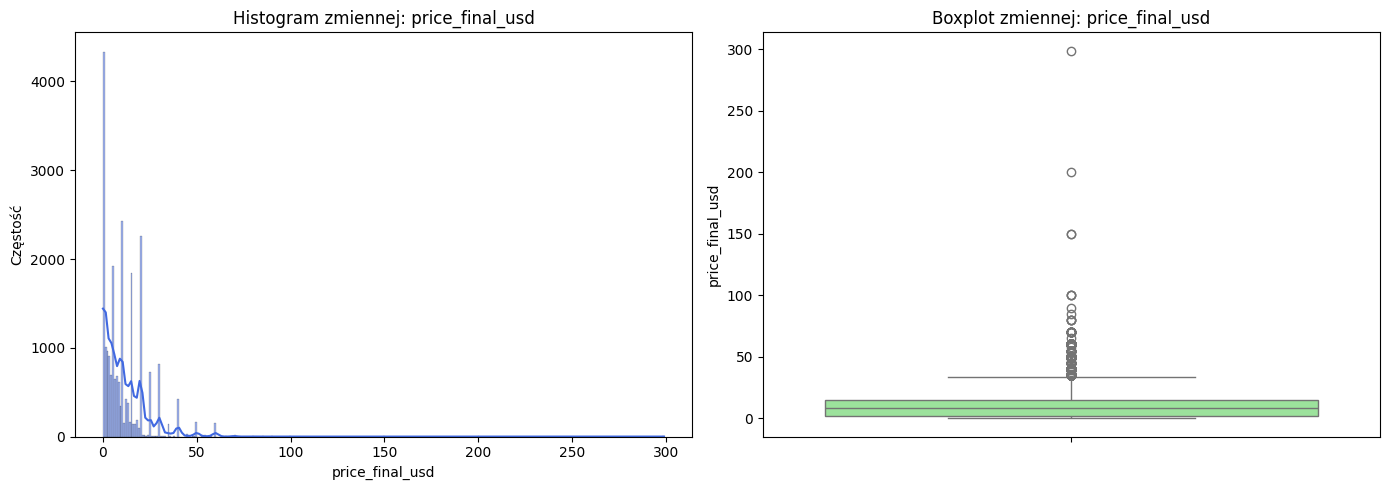

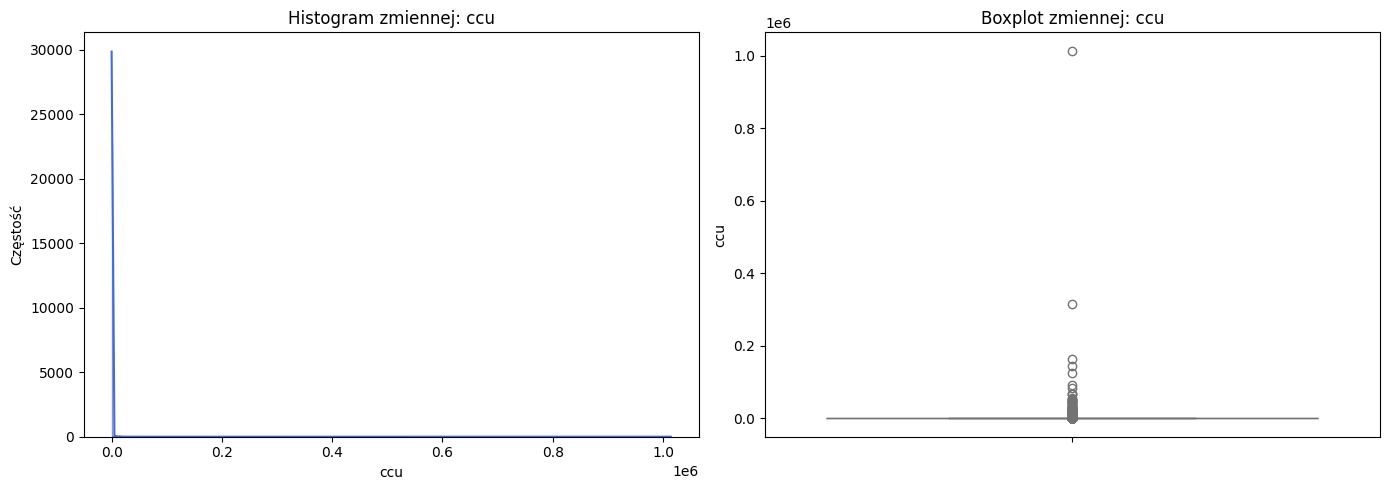

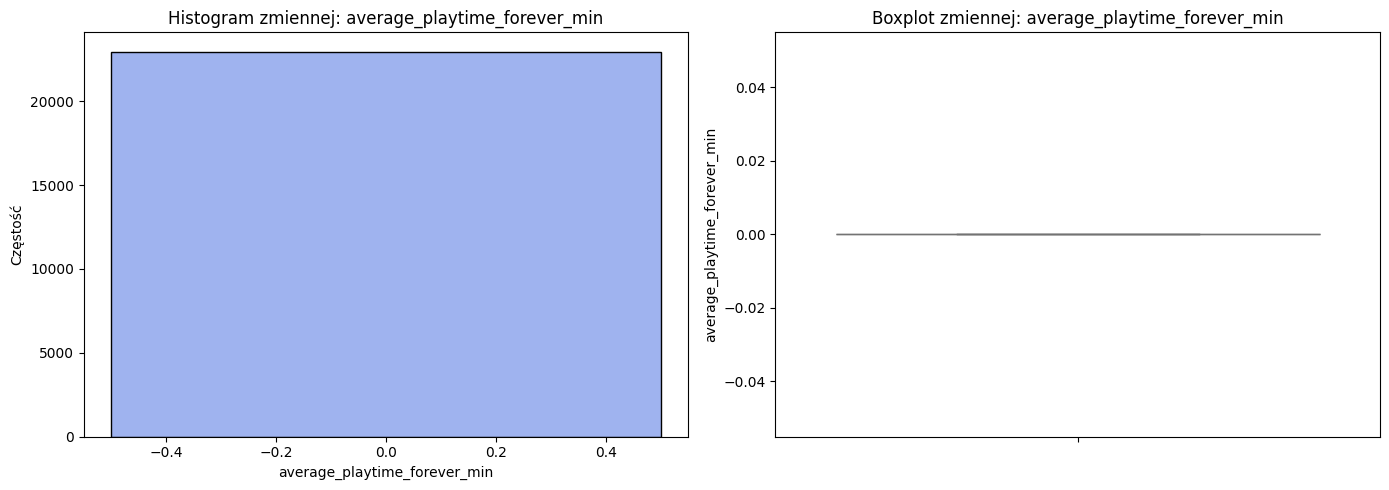

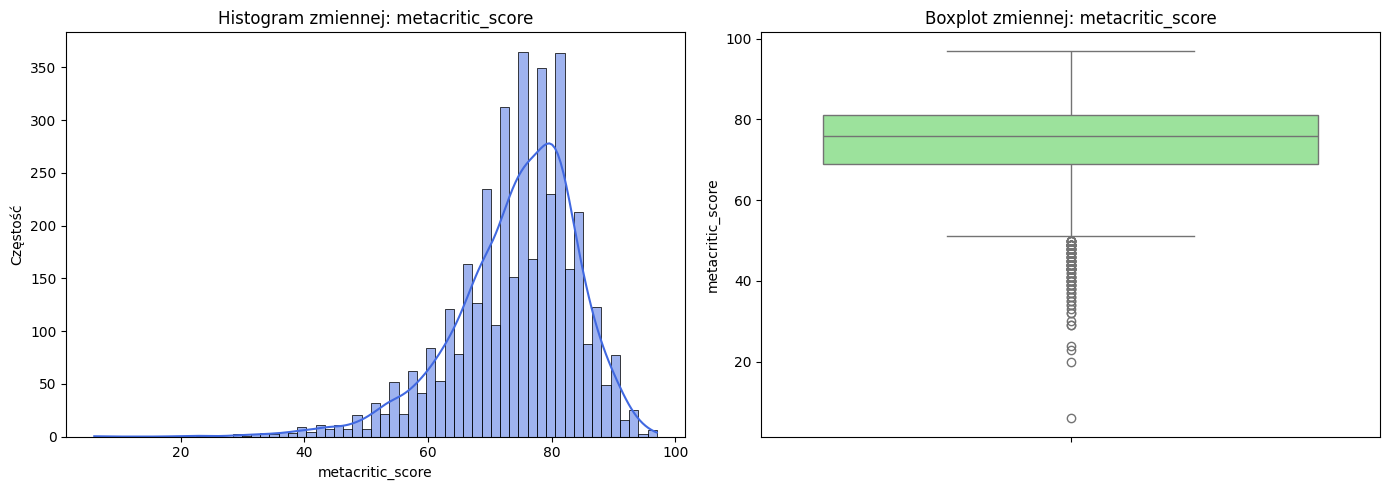

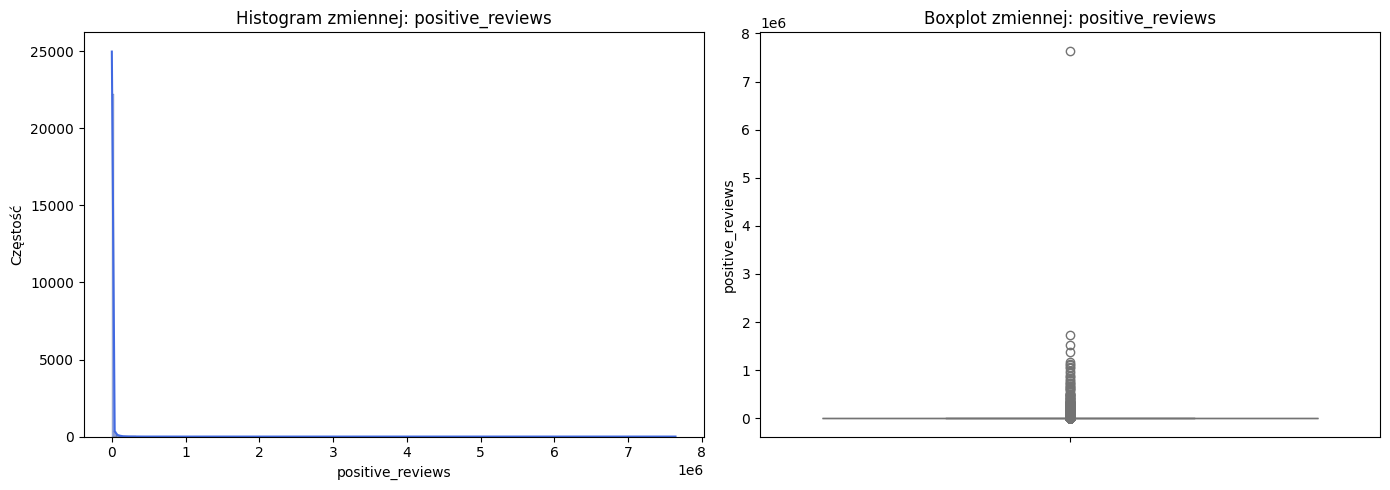

In [14]:
numeric_cols = ['price_final_usd','ccu','average_playtime_forever_min','metacritic_score','positive_reviews']

for numeric_col in numeric_cols:
    if numeric_col in df_games.columns:
        plt.figure(figsize=(14, 5))

        plt.subplot(1, 2, 1)
        sns.histplot(df_games[numeric_col].dropna(), kde=True, color='royalblue')
        plt.title(f'Histogram zmiennej: {numeric_col}')
        plt.xlabel(numeric_col)
        plt.ylabel('Częstość')

        plt.subplot(1, 2, 2)
        sns.boxplot(y=df_games[numeric_col], color='lightgreen')
        plt.title(f'Boxplot zmiennej: {numeric_col}')
        plt.ylabel(numeric_col)
        plt.tight_layout()
        plt.show()

Większość gier na platformie jest "tania", co widać po wysokim słupku przy wartościach bliskich zeru na histogramie.

Rozkład zmiennej dotyczącej aktualnej liczby graczy jest skrajnie prawoskośny. Przeważająca większość gier ma zerową lub znikomą liczbę jednoczesnych graczy

Wykresy dla czasu spędznaego w grze przez graczy potwierdzają wcześniejsze spostrzeżenie z analizy statystyk opisowych: kolumna ta nie zawiera żadnych użytecznych danych.

Rozkład ocen z Metacritic przypomina rozkład normalny, ale jest lekko lewoskośny. Zdecydowana większość gier otrzymuje oceny w przedziale od 60 do 90 punktów, z medianą wynoszącą około 75. Gry z ocenami poniżej 50 są rzadkością. Wskazuje to, że recenzenci na Metacritic rzadko przyznają bardzo niskie noty, albo że gry słabe po prostu nie są recenzowane.

Z histogramu wynika, że przeważająca większość gier na platformie posiada bardzo małą liczbę pozytywnych recenzji, co widać po ogromnym piku przy wartościach bliskich zeru.



Tabela częstości: GENRES
                          genres  count  percentage
0                  Action, Indie   1136    4.948166
1       Action, Adventure, Indie   1122    4.887185
2               Adventure, Indie   1114    4.852339
3                         Action    949    4.133635
4       Adventure, Casual, Indie    687    2.992421
5                  Casual, Indie    644    2.805122
6              Action, Adventure    598    2.604757
7                      Adventure    555    2.417458
8  Action, Adventure, Indie, RPG    472    2.055928
9                       Strategy    436    1.899120


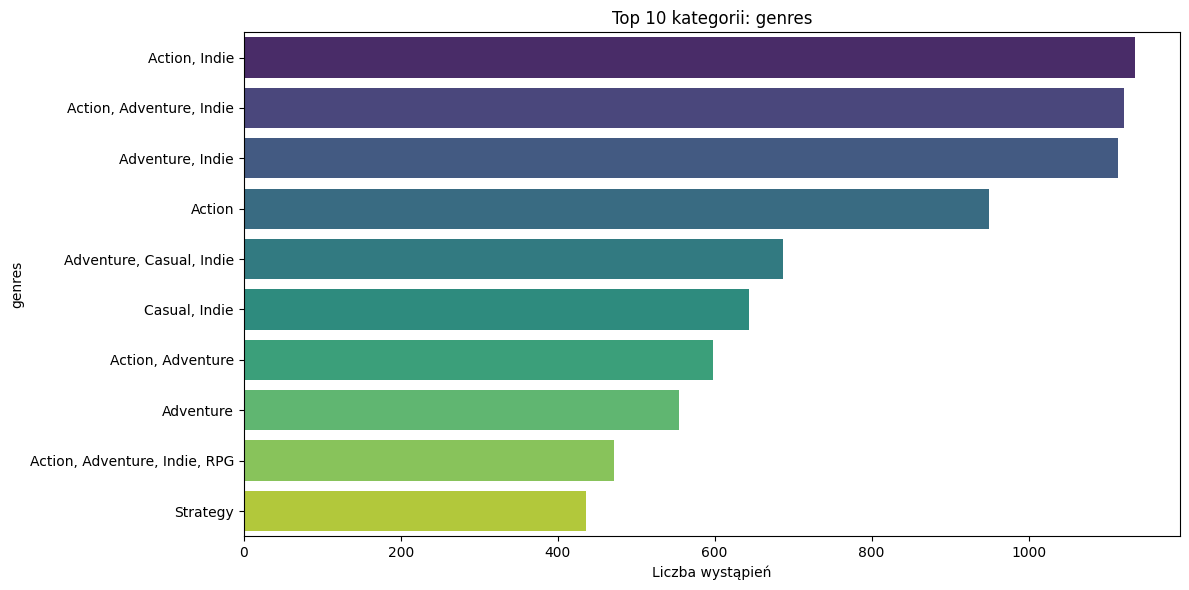


Tabela częstości: CATEGORIES
                                          categories  count  percentage
0                      Single-player, Family Sharing   2071    9.020821
1  Single-player, Steam Achievements, Family Sharing   1145    4.987368
2  Single-player, Steam Achievements, Steam Cloud...    850    3.702413
3  Single-player, Steam Achievements, Steam Tradi...    727    3.166652
4  Single-player, Steam Achievements, Full contro...    641    2.792055
5  Single-player, Steam Achievements, Steam Tradi...    620    2.700584
6         Single-player, Steam Cloud, Family Sharing    485    2.112553
7  Single-player, Steam Achievements, Full contro...    471    2.051572
8  Single-player, Steam Achievements, Full contro...    400    1.742312
9  Single-player, Steam Trading Cards, Family Sha...    393    1.711822


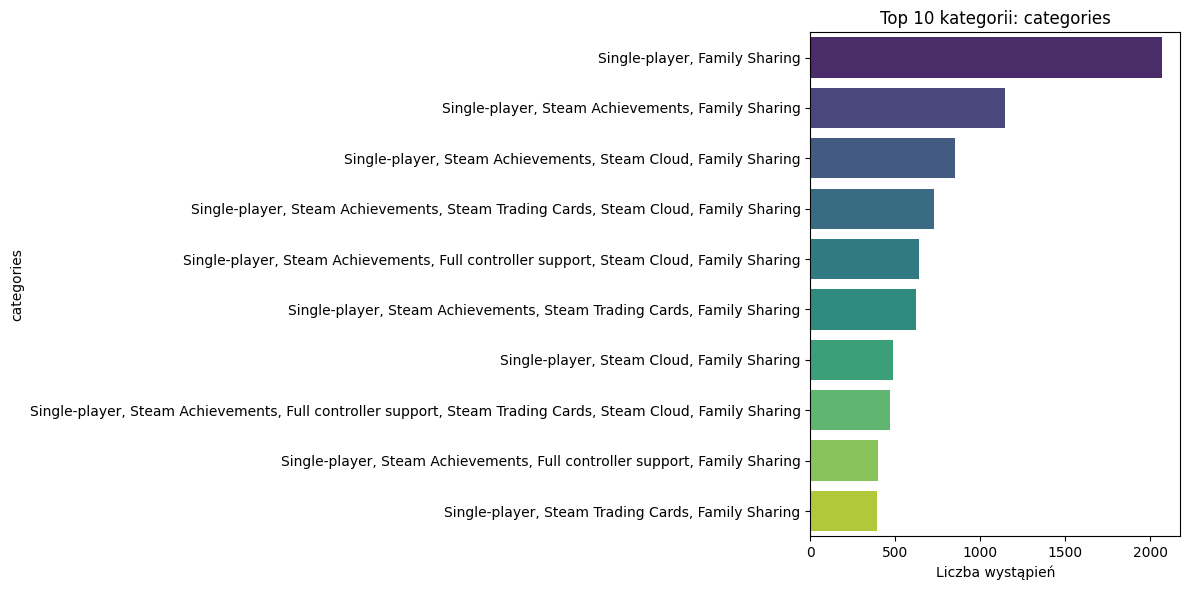


Tabela częstości: PUBLISHERS
           publishers  count  percentage
0                        179    0.779685
1             Ubisoft    140    0.609809
2          THQ Nordic    136    0.592386
3         Square Enix    134    0.583675
4     Electronic Arts    124    0.540117
5        Kagura Games    122    0.531405
6                SEGA    116    0.505270
7    Devolver Digital    116    0.505270
8  Fulqrum Publishing     90    0.392020
9       Sekai Project     87    0.378953


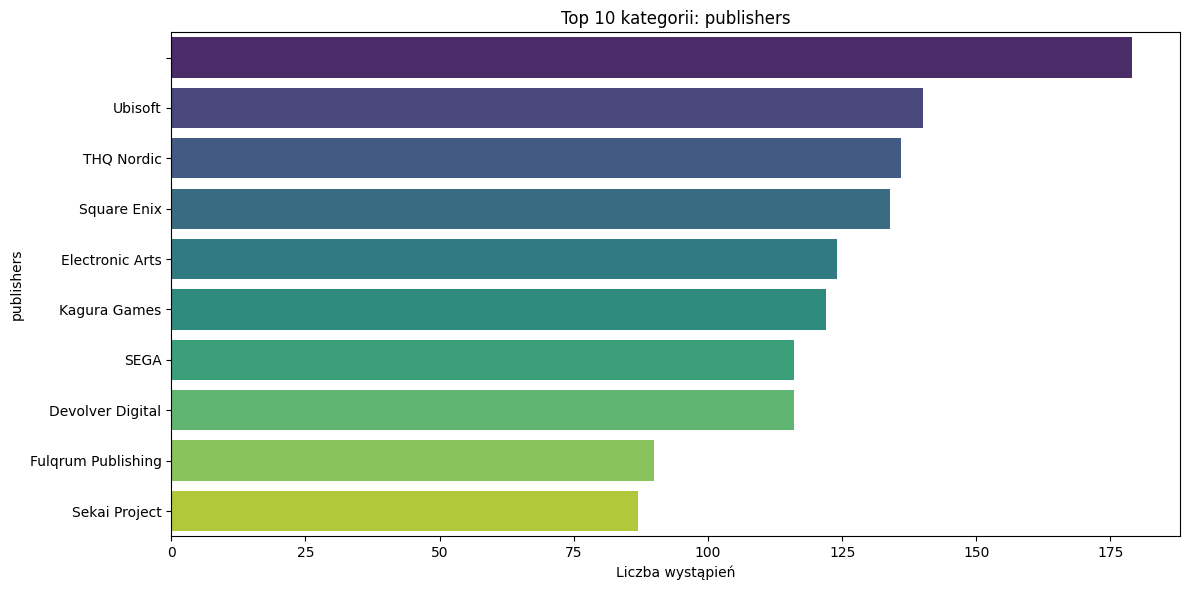


Tabela częstości: DEVELOPERS
                   developers  count  percentage
0  KOEI TECMO GAMES CO., LTD.     82    0.357174
1                                 57    0.248279
2                 Square Enix     52    0.226501
3            CAPCOM Co., Ltd.     44    0.191654
4            Milestone S.r.l.     41    0.178587
5                       Valve     34    0.148097
6             HeR Interactive     30    0.130673
7           Kairosoft Co.,Ltd     30    0.130673
8                Winged Cloud     29    0.126318
9             Ripknot Systems     29    0.126318


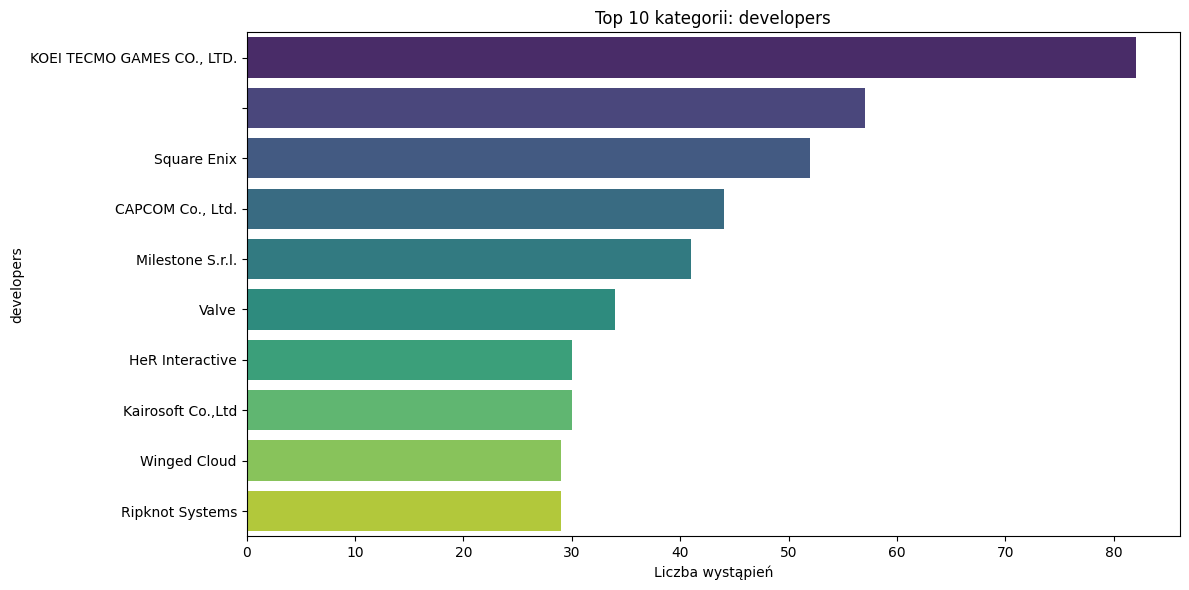

In [15]:
cat_cols = ['genres', 'categories', 'publishers', 'developers']

for cat_col in cat_cols:
    if cat_col in df_games.columns:
        freq_table = df_games[cat_col].value_counts().reset_index()
        freq_table.columns = [cat_col, 'count']
        freq_table['percentage'] = (freq_table['count'] / len(df_games)) * 100

        print(f"\nTabela częstości: {cat_col.upper()}")
        print(freq_table.head(10))

        plt.figure(figsize=(12, 6))
        sns.barplot(
            data=freq_table.head(10),
            x='count',
            y=cat_col,
            hue=cat_col,
            palette='viridis',
            legend=False
        )

        plt.title(f'Top 10 kategorii: {cat_col}')
        plt.xlabel('Liczba wystąpień')
        plt.ylabel(cat_col)
        plt.tight_layout()
        plt.show()


Wśród najpopularniejszych pod względem ich występowania gatunków na platformie absolutnie dominuje tag "Indie", który wchodzi w skład pięciu z sześciu najczęstszych kombinacji. Twórcy najczęściej łączą go z grami akcji ("Action, Indie" - 1136 gier) oraz przygodowymi ("Action, Adventure, Indie" i "Adventure, Indie", łącznie obejmujące kolejne blisko 10% rynku).

Najwięcej gier skupiają się na rozgrywce solowej. Kombinacja "Single-player" oraz "Family Sharing" dominuje inne zestawienia, pojawiając się w 2071 tytułach.

Rynek gier na Steam jest bardzo pofragmentowany. Najwięksi branżowi giganci, tacy jak Ubisoft 140 gier, THQ Nordic 136 gier, Square Enix 134 gry czy Electronic Arts 124 gry, odpowiadają jednostkowo za zaledwie 0,5% do 0,6% całego zbioru. Podobnie wygląda sytuacja wśród twórców największy zidentyfikowany w danych deweloper, KOEI TECMO GAMES CO., LTD., ma na koncie jedynie 82 gry, co stanowi zaledwie 0,36% wszystkich tytułów.

Zestawienia kategoryczne ujawniają istotny problem z jakością danych: w kolumnach publishers oraz developers występują puste wartości znakowe.

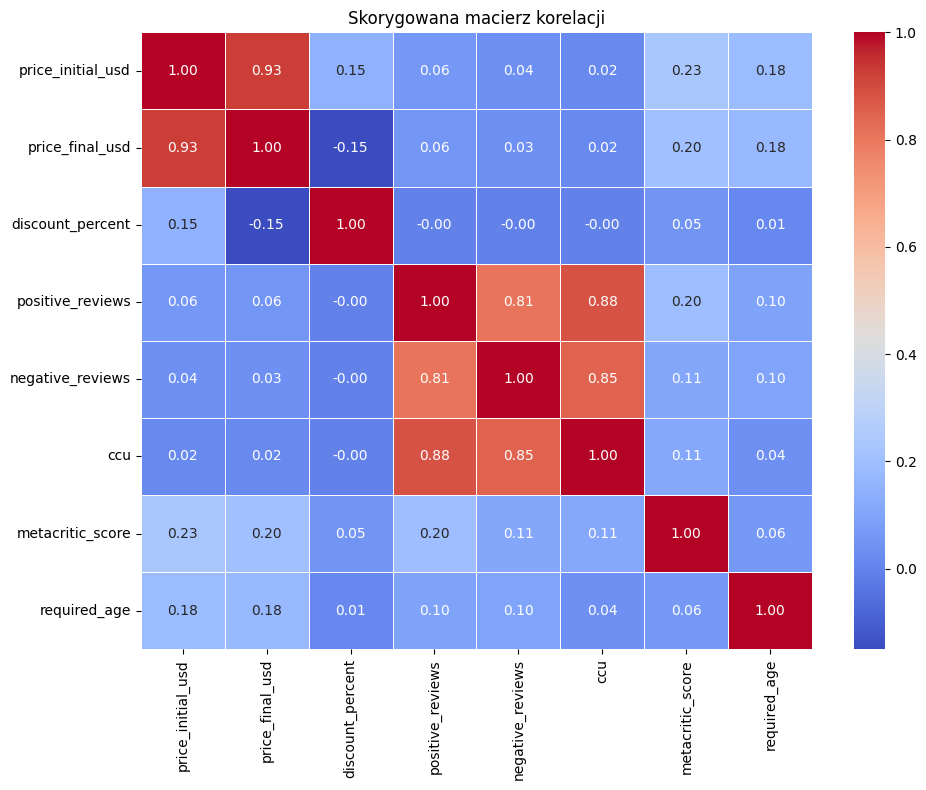

In [16]:
cols_to_drop = [
    'app_id',
    'average_playtime_forever_min',
    'median_playtime_forever_min',
    'total_recommendations'
]

plt.figure(figsize=(10, 8))
corr_matrix = df_games.drop(columns=cols_to_drop).select_dtypes(include=['number']).corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Skorygowana macierz korelacji')
plt.tight_layout()
plt.show()

Zmienne positive_reviews, negative_reviews oraz ccu tworzą grupę o bardzo silnych korelacjach dodatnich, od 0,81 do 0,88. Wniosek z tego jest dosyć prosty. Gry, w które gra dużo osób, generują ogromny ruch w recenzjach zarówno tych pozytywnych, jak i negatywnych. Te trzy zmienne nie mierzą samej jakości gry, ale przede wszystkim jej skalę i popularność.

wykazuje stosunkowo słabe powiązania z resztą danych. Najsilniej koreluje z ceną początkową 0,23 oraz końcową 0,20 co może sugerować, że droższe gry często oznaczające większe budżety lub produkcje AAA otrzymują nieznacznie wyższe noty od recenzentów. Posiada też słabą korelację z liczbą pozytywnych recenzji od graczy 0,20.

Zmienna required_age jest praktycznie niezależna od pozostałych metryk, wykazując jedynie śladową korelację z ceną 0,18.

/tmp/ipykernel_906/1695777772.py:8: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




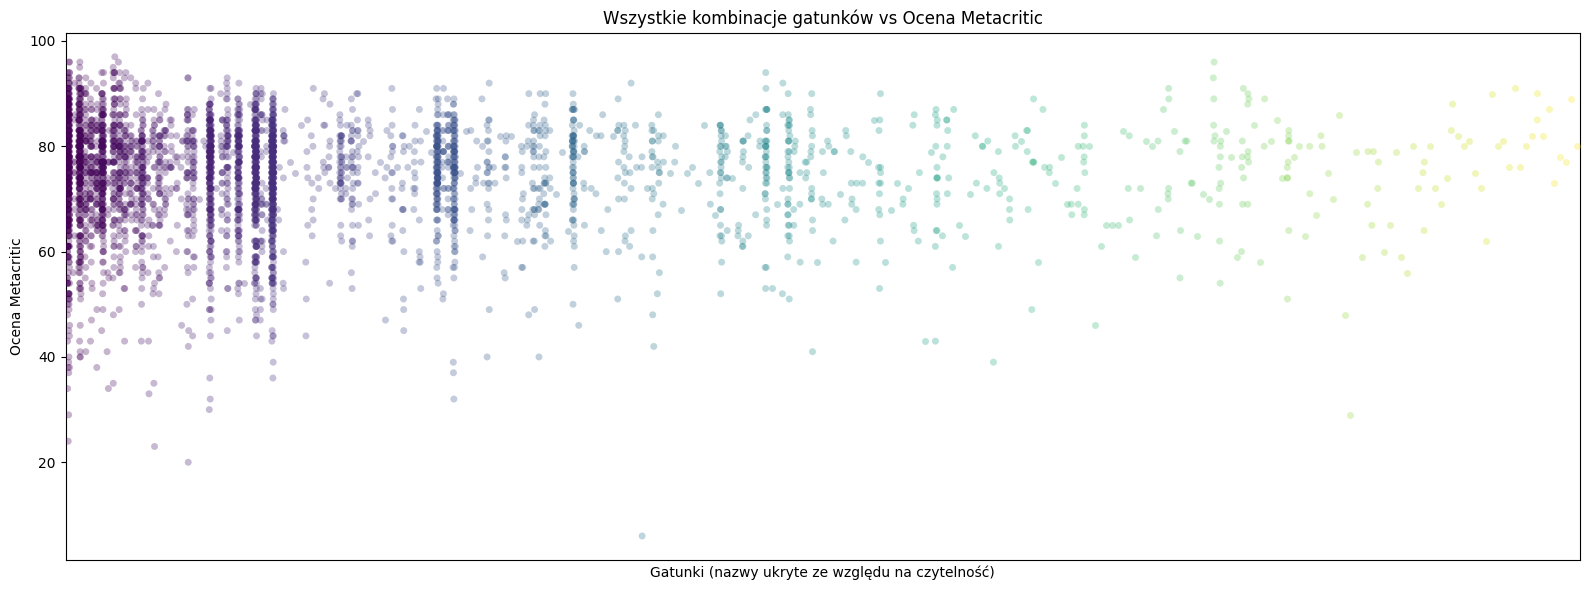

/tmp/ipykernel_906/1695777772.py:34: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




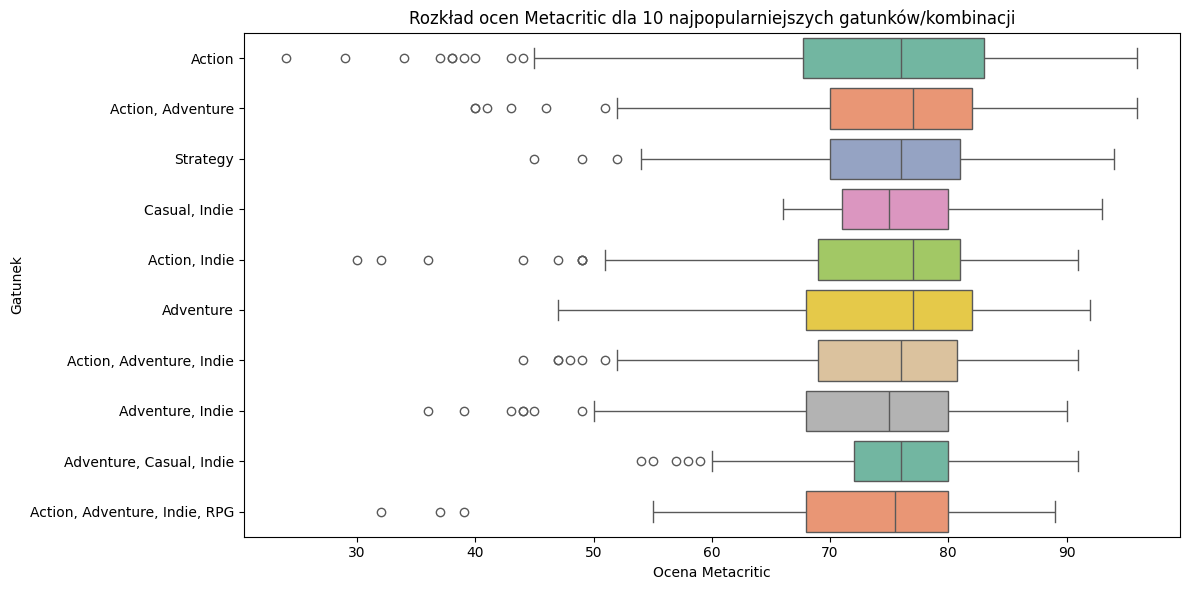

In [17]:
x_var = 'genres'
y_var = 'metacritic_score'

if x_var in df_games.columns and y_var in df_games.columns:
    plot_data = df_games.dropna(subset=[y_var]).copy()
    if not plot_data.empty:
        plt.figure(figsize=(16, 6))
        sns.stripplot(
            data=plot_data,
            x=x_var,
            y=y_var,
            alpha=0.3,
            palette='viridis',
            jitter=0.2,
            legend=False
        )

        plt.title('Wszystkie kombinacje gatunków vs Ocena Metacritic')
        plt.xlabel('Gatunki (nazwy ukryte ze względu na czytelność)')
        plt.ylabel('Ocena Metacritic')
        plt.xticks([])
        plt.tight_layout()
        plt.show()


if x_var in df_games.columns and y_var in df_games.columns:
    top_genres = df_games[x_var].value_counts().head(10).index
    plot_data = df_games[df_games[x_var].isin(top_genres)].copy()
    plot_data = plot_data.dropna(subset=[y_var])

    if not plot_data.empty:
        plt.figure(figsize=(12, 6))

        sns.boxplot(
            data=plot_data,
            x=y_var,
            y=x_var,
            palette='Set2'
        )

        plt.title('Rozkład ocen Metacritic dla 10 najpopularniejszych gatunków/kombinacji')
        plt.xlabel('Ocena Metacritic')
        plt.ylabel('Gatunek')
        plt.tight_layout()
        plt.show()

Pierwszy wykres pokazuję problem z kategoryzowaniem gier na platformie Steam. Gatunki to w rzeczywistości kombinacje tagów, których jest tak wiele, że oś X stała się całkowicie nieczytelną plamą tekstu (Na potrzeby prezentacji usunięto tekst z osi X) Wykres punktowy pokazuje jednak ważną tendencję - niezależnie od tego, jaka to jest kombinacja gatunków, oceny Metacritic dla ogromnej większości z nich oscylują w przedziale od 60 do 90 punktów. Nie widać tu jednej, specyficznej kombinacji gatunków, która systematycznie dostawałaby oceny z samego dołu lub samej góry skali.

Wykres pudełkowi dostarcza nam więcej informacji. Mediany ocen dla wszystkich topowych gatunków są bardzo do siebie zbliżone i wynoszą około 75 punktów. Sugeruje to, że sam ogólny gatunek ma stosunkowo niewielki wpływ na ostateczną notę krytyków.